In [1]:
from nuscenes.nuscenes import NuScenes
nusc = NuScenes(version='v1.0-mini', dataroot='DATA/', verbose=True)

Loading NuScenes tables for version v1.0-mini...
23 category,
8 attribute,
4 visibility,
911 instance,
12 sensor,
120 calibrated_sensor,
31206 ego_pose,
8 log,
10 scene,
404 sample,
31206 sample_data,
18538 sample_annotation,
4 map,
Done loading in 0.973 seconds.
Reverse indexing ...
Done reverse indexing in 0.1 seconds.


In [2]:
import json
with open('DATA/v1.0-mini/category.json','r') as f:
    categories = json.load(f)
token2category = {c['token']:c['name'] for c in categories}
with open('DATA/v1.0-mini/visibility.json','r') as f:
    visibility = json.load(f)
token2visible = {v['token']:v['level'] for v in visibility}
with open('DATA/v1.0-mini/attribute.json','r') as f:
    attributes = json.load(f)
token2attribute = {a['token']:a['name'] for a in attributes}
with open('DATA/v1.0-mini/instance.json','r') as f:
    instances = json.load(f)
with open('DATA/v1.0-mini/ego_pose.json','r') as f:
    ego_poses = json.load(f)
token2ego_pose = {p['token']:{'translation':p['translation'],'rotation':p['rotation']} for p in ego_poses}
with open('DATA/v1.0-mini/calibrated_sensor.json','r') as f:
    calibrated = json.load(f)
token2calibrate = {c['token']:{'translation':c['translation'], 'rotation':c['rotation'], 'camera_intrinsic':c['camera_intrinsic']} for c in calibrated}

In [43]:
p = []
for num, i in enumerate(instances):
    temp, index = {}, 1
    if token2category[i['category_token']] == 'human.pedestrian.adult':
        temp['category'] = 'human.pedestrian.adult'
        temp['length'] = i['nbr_annotations']
        anno, next_token = [], i['first_annotation_token']
        while next_token != '':
            data = nusc.get('sample_annotation',next_token)
            sample = nusc.get('sample', data['sample_token'])
            anno_cell = {
                'index': index,
                'visibility': token2visible[data['visibility_token']],
                'attribute': token2attribute[data['attribute_tokens'][0]],
                'translation': data['translation'],
                'size': data['size'],
                'rotation': data['rotation'],
                'num_lidar_pts': data['num_lidar_pts'],
                'num_radar_pts': data['num_radar_pts'],
            }
            data_cells = {}
            for k in sample['data'].keys():
                data_cell = {}
                temp_data = nusc.get('sample_data',sample['data'][k])
                data_cell['file_path'] = temp_data['filename']
                data_cell['ego_pose'] = token2ego_pose[temp_data['ego_pose_token']]
                data_cell['calibrated_sensor'] = token2calibrate[temp_data['calibrated_sensor_token']]
                data_cells[k] = data_cell
            anno_cell['data'] = data_cells
            anno.append(anno_cell)
            next_token = data['next']
            index += 1
        temp['annotations'] = anno
        p.append(temp)
        break
# nusc.render_instance(i['token'])

In [26]:
nusc.get_sample_data('fca0353274424116948fa1f10be1fc29')[1]

[label: nan, score: nan, xyz: [19.99, 37.80, 0.18], wlh: [0.62, 0.67, 1.64], rot axis: [0.01, -0.02, 1.00], ang(degrees): 177.02, ang(rad): 3.09, vel: nan, nan, nan, name: human.pedestrian.adult, token: a2b20cdbf1ed4018ac795b8845d5deaa,
 label: nan, score: nan, xyz: [22.06, 17.29, -0.56], wlh: [0.78, 0.77, 1.71], rot axis: [-0.03, 0.01, -1.00], ang(degrees): -85.25, ang(rad): -1.49, vel: nan, nan, nan, name: human.pedestrian.adult, token: c6d92f8785e443309d79fda6dbf5ac12,
 label: nan, score: nan, xyz: [39.13, 42.02, -0.04], wlh: [2.01, 4.63, 1.57], rot axis: [0.01, -0.02, 1.00], ang(degrees): 175.00, ang(rad): 3.05, vel: nan, nan, nan, name: vehicle.car, token: b80e6e94bc074092bfd1479d89eae691,
 label: nan, score: nan, xyz: [25.76, 6.91, -0.83], wlh: [0.75, 0.82, 1.64], rot axis: [-0.01, -0.03, 1.00], ang(degrees): -97.13, ang(rad): -1.70, vel: nan, nan, nan, name: human.pedestrian.adult, token: 550ecacb368b4d288cdc3951597383ce,
 label: nan, score: nan, xyz: [5.56, -36.74, -2.60], wlh:

In [16]:
nusc.get('sample_annotation','a2b20cdbf1ed4018ac795b8845d5deaa')

{'token': 'a2b20cdbf1ed4018ac795b8845d5deaa',
 'sample_token': 'f1e3d9d08f044c439ce86a2d6fcca57b',
 'instance_token': '6dd2cbf4c24b4caeb625035869bca7b5',
 'visibility_token': '1',
 'attribute_tokens': ['4d8821270b4a47e3a8a300cbec48188e'],
 'translation': [373.256, 1130.419, 0.792],
 'size': [0.621, 0.669, 1.642],
 'rotation': [0.9831098797903927, 0.0, 0.0, -0.18301629506281616],
 'prev': '060be69422ee4b2a8b239b463b995e92',
 'next': '05e0ad1194804f548be544f2267c7e74',
 'num_lidar_pts': 1,
 'num_radar_pts': 0,
 'category_name': 'human.pedestrian.adult'}

In [47]:
nusc.get('sample','f1e3d9d08f044c439ce86a2d6fcca57b')

{'token': 'f1e3d9d08f044c439ce86a2d6fcca57b',
 'timestamp': 1532402930152601,
 'prev': 'c923fe08b2ff4e27975d2bf30934383b',
 'next': '4f545737bf3347fbbc9af60b0be9a963',
 'scene_token': 'cc8c0bf57f984915a77078b10eb33198',
 'data': {'RADAR_FRONT': '941dc57a0b9b47a0808bd3f272cf90fe',
  'RADAR_FRONT_LEFT': '77acaa656cbd41309cefd1f52e38d0b7',
  'RADAR_FRONT_RIGHT': '669691fb761e4fe4a82c5e85c1bbeedc',
  'RADAR_BACK_LEFT': 'f69003cc8bb0433c91340475cff7c798',
  'RADAR_BACK_RIGHT': '082a29888e8a44aa9b1fdbc0933eff1d',
  'LIDAR_TOP': 'fca0353274424116948fa1f10be1fc29',
  'CAM_FRONT': 'ddbc1befa70f4b49a0824f63a920676b',
  'CAM_FRONT_RIGHT': 'c22c792ba1d448feba303495ebda3e3b',
  'CAM_BACK_RIGHT': 'a1e783e1c8c1482e96cacbbd130b61e9',
  'CAM_BACK': 'c2dc484b195f4bce9eed1ef604be8270',
  'CAM_BACK_LEFT': 'ceeec46bb59d4bd3afc316996aee8f97',
  'CAM_FRONT_LEFT': '084af9b8a7804851842c8996ca8388df'},
 'anns': ['a2b20cdbf1ed4018ac795b8845d5deaa',
  'c6d92f8785e443309d79fda6dbf5ac12',
  'b80e6e94bc074092bfd1479

In [12]:
from nuscenes.nuscenes import NuScenes
from nuscenes.utils.geometry_utils import view_points
from pyquaternion import Quaternion
import numpy as np
np.set_printoptions(suppress=True)
sensor_channels = ['CAM_FRONT', 'CAM_FRONT_LEFT', 'CAM_FRONT_RIGHT', 
                   'CAM_BACK', 'CAM_BACK_LEFT', 'CAM_BACK_RIGHT']
for s in sensor_channels:
    annotation = nusc.get('sample_annotation','a2b20cdbf1ed4018ac795b8845d5deaa')
    sample = nusc.get('sample',annotation['sample_token'])
    cam_token = sample['data'][s]
    cam_data = nusc.get('sample_data', cam_token)
    calib = nusc.get('calibrated_sensor', cam_data['calibrated_sensor_token'])
    ego_pose = nusc.get('ego_pose',cam_data['ego_pose_token'])
    box = nusc.get_box(annotation['token'])
    corners_3d = box.corners()
    corners_3d -= np.array(ego_pose['translation']).reshape(3, 1)
    corners_3d = Quaternion(ego_pose['rotation']).inverse.rotation_matrix @ corners_3d
    corners_3d -= np.array(calib['translation']).reshape(3, 1)
    corners_3d = Quaternion(calib['rotation']).inverse.rotation_matrix @ corners_3d
    corners_img = view_points(corners_3d, view=np.array(calib['camera_intrinsic']), normalize=True)
    
    in_front = corners_3d[2, :] > 0.1  # 排除相机后面的点
    in_image = (corners_img[0, :] > 0) & (corners_img[0, :] < 1600) & (corners_img[1, :] > 0) & (corners_img[1, :] < 900)
    
    x_min = max(0, int(np.min(corners_img[0, corners_3d[2, :] > 0.1])))
    y_min = max(0, int(np.min(corners_img[1, corners_3d[2, :] > 0.1])))
    x_max = min(1600, int(np.max(corners_img[0, corners_3d[2, :] > 0.1])))
    y_max = min(900, int(np.max(corners_img[1, corners_3d[2, :] > 0.1])))
    if any(in_front & in_image) and x_min < x_max and y_min < y_max:
        print(f"标注出现{s}:({x_min},{y_min}),({x_max},{y_max})")
        print(np.mean(box.corners(), axis=-1))
        break

标注出现CAM_FRONT:(1481,474),(1517,530)
[ 373.256 1130.419    0.792]


In [7]:
import numpy as np
from pyquaternion import Quaternion

def project_2d_to_3d(u, v, K, cam_height=1.5, cam_rotation=None, cam_translation=None, ego_rotation=None, ego_translation=None):
    """将2D点投影到3D地面"""
    # 计算射线方向（相机坐标系）
    ray_dir = np.linalg.inv(K) @ np.array([u, v, 1])
    
    # 地面平面方程：z = -h
    scale = cam_height / ray_dir[1]
    point_3d_cam = scale * ray_dir
    
    # 转换到全局坐标系（如有外参）
    if cam_rotation and cam_translation:
        point_3d_global = Quaternion(cam_rotation).rotate(point_3d_cam) + cam_translation
        if ego_rotation and ego_translation:
            point_3d_global = Quaternion(ego_rotation).rotate(point_3d_cam) + ego_translation
        return point_3d_global
    return point_3d_cam

# 示例：nuScenes 相机数据
cam_data = nusc.get('sample_data','ddbc1befa70f4b49a0824f63a920676b')
calib = nusc.get('calibrated_sensor', cam_data['calibrated_sensor_token'])
ego_pose = nusc.get('ego_pose',cam_data['ego_pose_token'])
h = calib['translation'][-1]+ego_pose['translation'][-1]
K = np.array(calib['camera_intrinsic'])
u, v = (x_min+x_max)/2, y_max  # 检测框底边中点
point_3d = project_2d_to_3d(u, v, K, cam_height=h, 
                           cam_rotation=calib['rotation'], 
                           cam_translation=calib['translation'],
                           ego_rotation=ego_pose['rotation'],
                           ego_translation=ego_pose['translation'])
print(u,v)
print("3D坐标:", point_3d)

1499.0 530
3D坐标: [ 398.09389095 1134.39386289   49.25634029]


In [11]:
h

1.51095763913

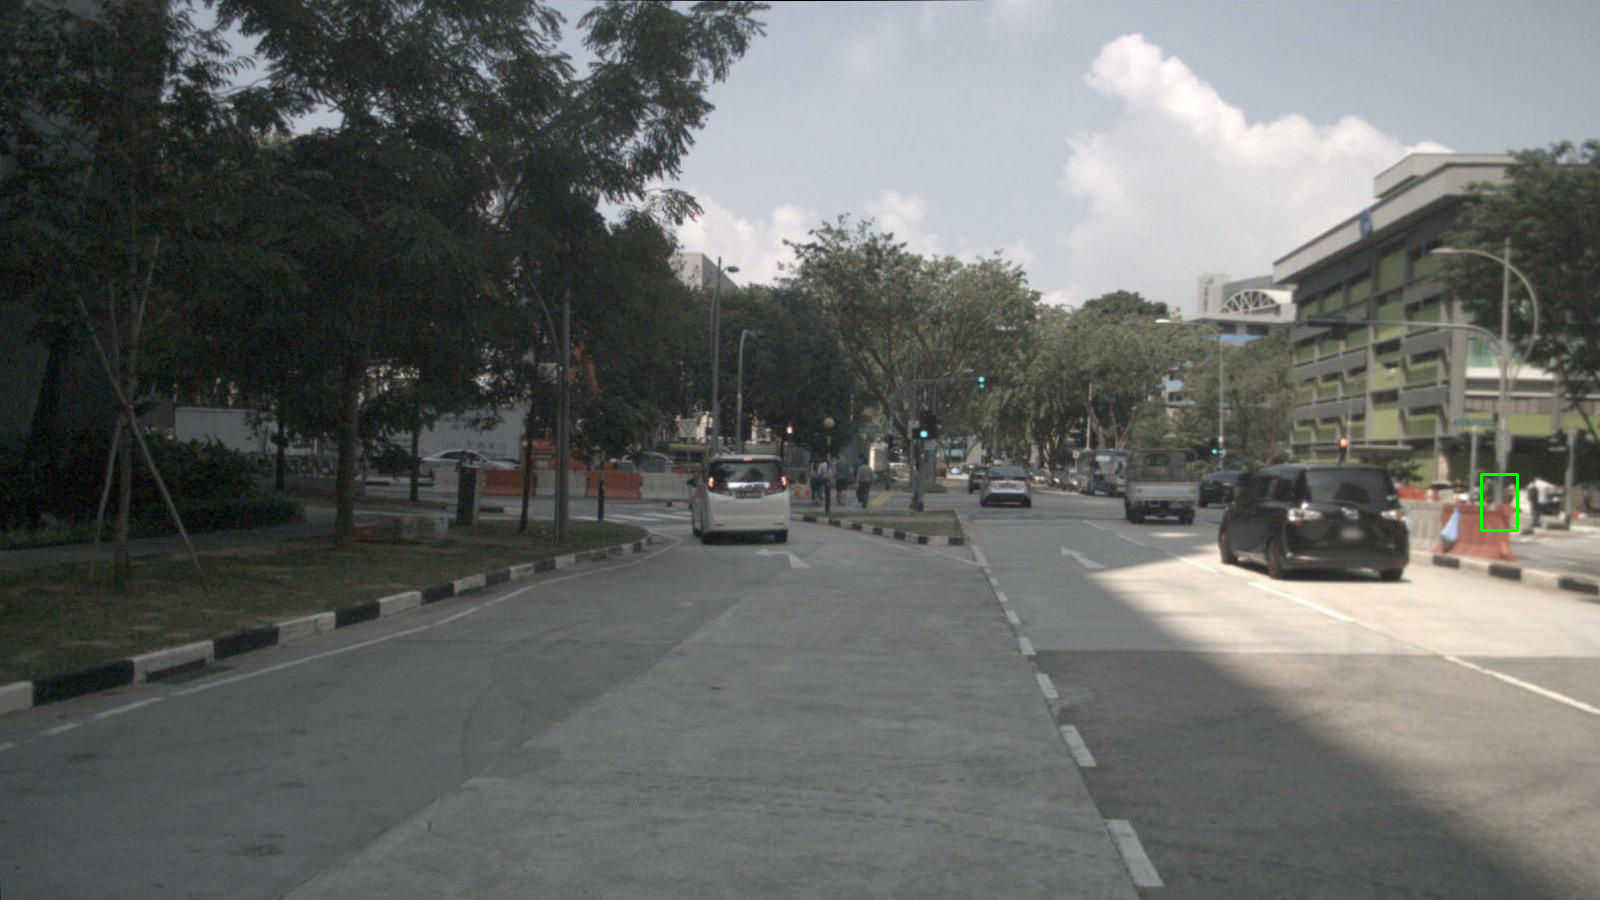

In [84]:
import cv2
from PIL import Image
img = cv2.imread('DATA/'+nusc.get('sample_data', 'ddbc1befa70f4b49a0824f63a920676b')['filename'])
cv2.rectangle(img, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2)
Image.fromarray(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))

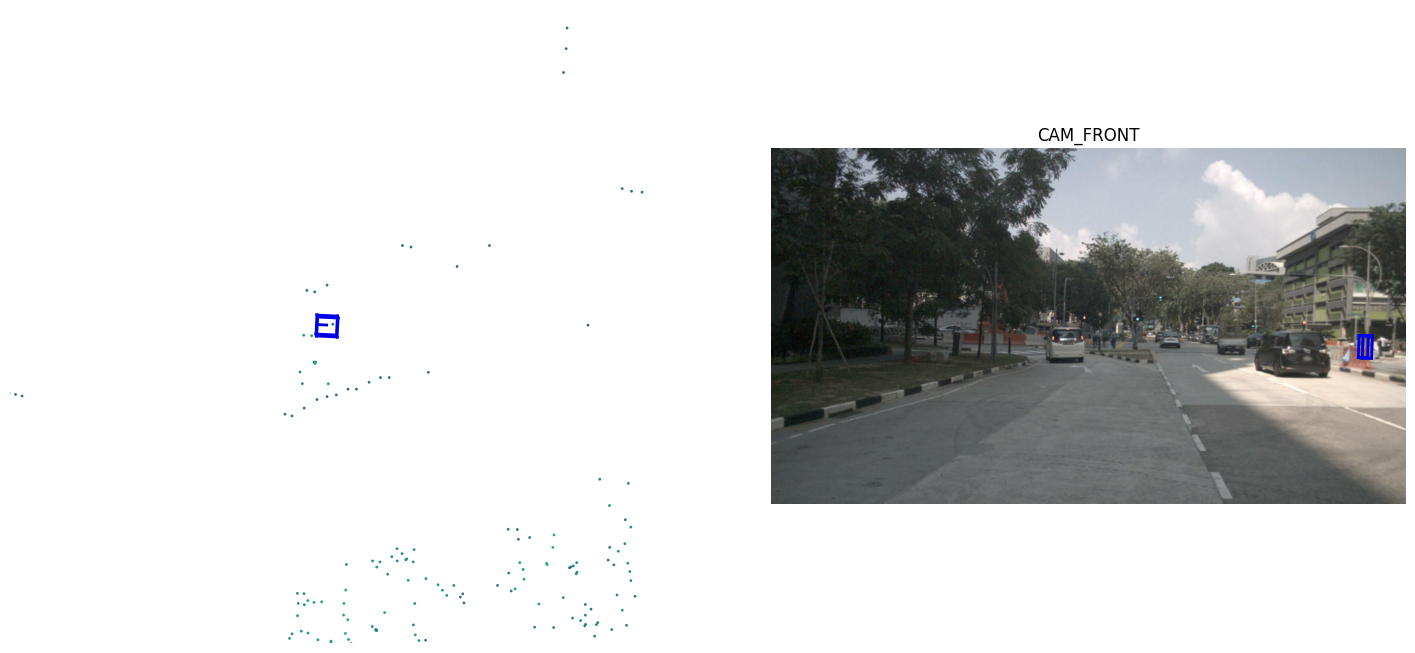

In [83]:
nusc.render_annotation('a2b20cdbf1ed4018ac795b8845d5deaa')

In [44]:
p[0]['annotations']

[{'index': 1,
  'visibility': 'v0-40',
  'attribute': 'pedestrian.standing',
  'translation': [373.256, 1130.419, 0.8],
  'size': [0.621, 0.669, 1.642],
  'rotation': [0.9831098797903927, 0.0, 0.0, -0.18301629506281616],
  'num_lidar_pts': 1,
  'num_radar_pts': 0,
  'data': {'RADAR_FRONT': {'file_path': 'samples/RADAR_FRONT/n015-2018-07-24-11-22-45+0800__RADAR_FRONT__1532402927664178.pcd',
    'ego_pose': {'translation': [411.25243634487725, 1180.7511754315697, 0.0],
     'rotation': [0.5721129977125774,
      -0.0014962022442161157,
      0.011922678049447764,
      -0.8200867813684729]},
    'calibrated_sensor': {'translation': [3.412, 0.0, 0.5],
     'rotation': [0.9999984769132877, 0.0, 0.0, 0.0017453283658983088],
     'camera_intrinsic': []}},
   'RADAR_FRONT_LEFT': {'file_path': 'samples/RADAR_FRONT_LEFT/n015-2018-07-24-11-22-45+0800__RADAR_FRONT_LEFT__1532402927652686.pcd',
    'ego_pose': {'translation': [411.28902020297073, 1180.8498228153214, 0.0],
     'rotation': [0.572059

In [39]:
nusc.get('sample_data','c02402396ad84679823fe41b11f70630')

{'token': 'c02402396ad84679823fe41b11f70630',
 'sample_token': '4f545737bf3347fbbc9af60b0be9a963',
 'ego_pose_token': 'c02402396ad84679823fe41b11f70630',
 'calibrated_sensor_token': 'f4d2a6c281f34a7eb8bb033d82321f79',
 'timestamp': 1532402930680594,
 'fileformat': 'pcd',
 'is_key_frame': True,
 'height': 0,
 'width': 0,
 'filename': 'samples/RADAR_FRONT/n015-2018-07-24-11-22-45+0800__RADAR_FRONT__1532402930680594.pcd',
 'prev': 'dec6cf6503e94b8b8e5edfdce5640046',
 'next': 'c0cc7e81e4b942c1948588d1c62655d2',
 'sensor_modality': 'radar',
 'channel': 'RADAR_FRONT'}

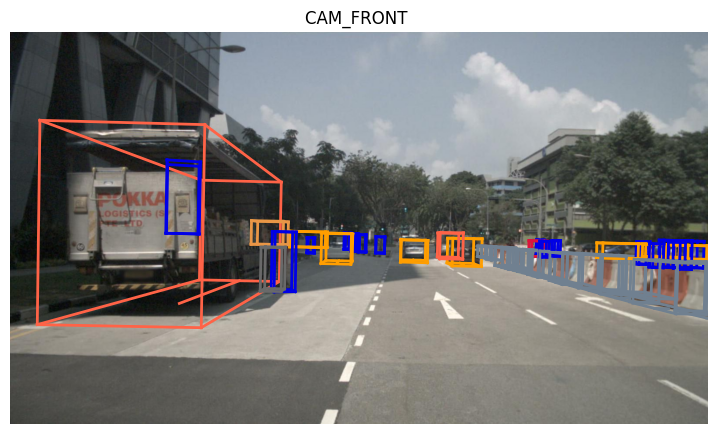

In [36]:
nusc.render_sample_data('e3d495d4ac534d54b321f50006683844')

In [40]:
nusc.get('calibrated_sensor','f4d2a6c281f34a7eb8bb033d82321f79')

{'token': 'f4d2a6c281f34a7eb8bb033d82321f79',
 'sensor_token': '47fcd48f71d75e0da5c8c1704a9bfe0a',
 'translation': [3.412, 0.0, 0.5],
 'rotation': [0.9999984769132877, 0.0, 0.0, 0.0017453283658983088],
 'camera_intrinsic': []}